In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [3]:
df = pd.read_csv("noisy_curvefit_data.csv")
df

,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
0,-1.000000,11.624419,8.296963,12.201067,7.811725,3.155566
1,-0.929293,10.377466,9.674440,12.198084,8.275006,7.518855
2,-0.858586,10.585100,9.251983,13.186565,12.926586,9.963630
3,-0.787879,10.913928,7.786344,12.552304,11.832379,9.625801
4,-0.717172,8.640287,8.551869,4.741432,8.790834,6.624113
...,...,...,...,...,...,...
95,5.717172,-1.411918,0.822231,-2.027132,-1.825106,2.746147
96,5.787879,0.344879,-1.718956,2.747559,-6.803779,-5.137472
97,5.858586,0.307133,0.353528,0.967976,5.461567,-0.905616
98,5.929293,0.048657,0.159961,2.482130,-0.414616,-4.334548


In [6]:
df.shape
# 100 rows, 6 columns

print(df.head())
print(df.tail())
# columns: x, y_noise_1, y_noise_2, y_noise_3, y_noise_4, y_noise_5

          x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0 -1.000000  11.624419   8.296963  12.201067   7.811725   3.155566
1 -0.929293  10.377466   9.674440  12.198084   8.275006   7.518855
2 -0.858586  10.585100   9.251983  13.186565  12.926586   9.963630
3 -0.787879  10.913928   7.786344  12.552304  11.832379   9.625801
4 -0.717172   8.640287   8.551869   4.741432   8.790834   6.624113
           x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
95  5.717172  -1.411918   0.822231  -2.027132  -1.825106   2.746147
96  5.787879   0.344879  -1.718956   2.747559  -6.803779  -5.137472
97  5.858586   0.307133   0.353528   0.967976   5.461567  -0.905616
98  5.929293   0.048657   0.159961   2.482130  -0.414616  -4.334548
99  6.000000  -0.193438  -2.244792   1.930035   4.992414  -6.872850


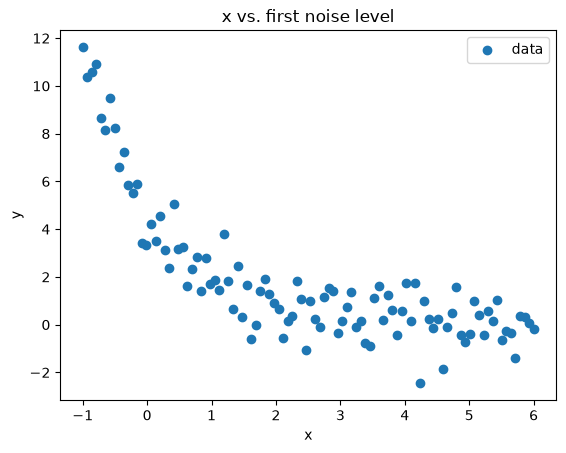

In [8]:
plt.figure()
plt.scatter(df["x"], df["y_noise_1"], label = "data")
plt.xlabel("x")
plt.ylabel("y")
plt.title("x vs. first noise level")
plt.legend()
plt.show()

In [11]:
def model(x, A, k):
    return A * np.exp(-k * x)
p0 = [1, 1]

popt, pcov = curve_fit(model, df["x"], df["y_noise_1"], p0=p0)
A_fit, k_fit = popt
print(f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)")

Fit: y = 4.71 * e^(-0.92 * x)


In [16]:
residuals = df["y_noise_1"] - model(df["x"], A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(df["x"]) - len(popt)
chi2_reduced = chi2 / dof
print(chi2_reduced)

0.7906732087457313


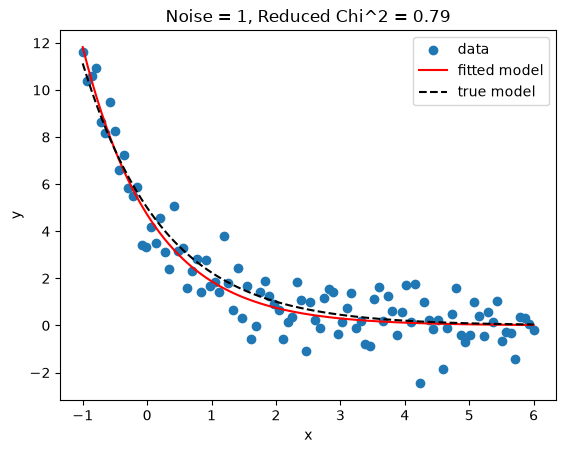

In [21]:
plt.figure()
plt.scatter(df["x"], df["y_noise_1"], label="data")
plt.plot(df["x"], 4.71 * np.exp(-0.92 * df["x"]), color="red", label="fitted model")
plt.plot(df["x"], model(df["x"], 5, 0.8), color="black", label="true model", linestyle="--")
plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Noise = 1, Reduced Chi^2 = {chi2_reduced:.2f}")
plt.legend()
plt.show()

In [38]:
def fit_model(x,y):
    popt, pcov = curve_fit(model, x, y, p0=p0)
    A_fit, k_fit = popt
    residuals = y - model(x, A_fit, k_fit)
    chi2 = np.sum((residuals)**2)
    dof = len(x) - len(popt)
    chi2_reduced = chi2 / dof
    return(popt, chi2_reduced)

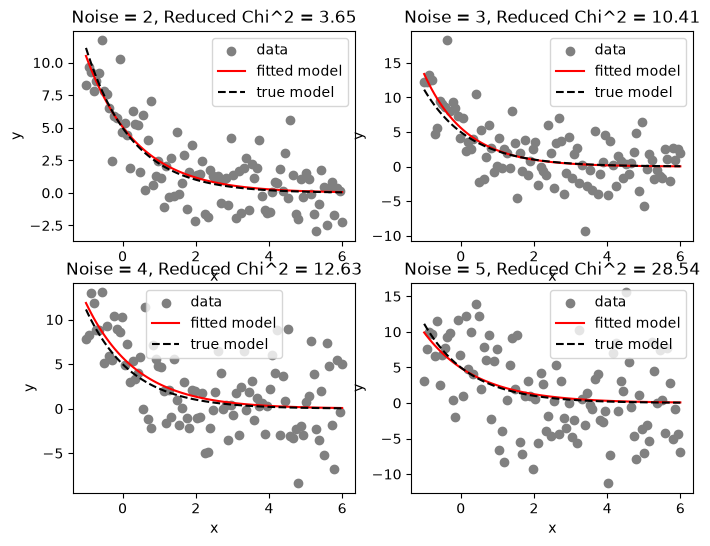

In [42]:
fig, axes = plt.subplots(2,2,figsize=(8,6))
noise_levels=[2,3,4,5]
axes = axes.flatten()
for ax, sigma in zip(axes, noise_levels):
    x = df["x"]
    y = df[f"y_noise_{sigma}"]
    popt, chi2_reduced = fit_model(x, y)  
    ax.scatter(x, y, color="grey", label="data")
    ax.plot(x, model(x, *popt), color="red", label="fitted model")
    ax.plot(x, model(x, 5, 0.8), color="black", label="true model", linestyle="--")
    ax.set_title(f"Noise = {sigma}, Reduced Chi^2 = {chi2_reduced:.2f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()
plt.show()

In [ ]:
# The fitted model less accurately fits the true model with more noise because the points are more spread out which affects the fitted curve in various places.
# Reduced chi-squared grows significantly with noise level because reduced chi-squared compares the residuals to noise levels.

In [50]:
noise=["1","2","3","4","5"]
data=[]
for i in noise:
    x = df["x"]
    y = df[f"y_noise_{i}"]
    popt, chi2_reduced = fit_model(x, y)
    A_fit, k_fit = popt
    data.append({
        "noise": i,
        "A_fit": A_fit,
        "k_fit": k_fit,
        "chi2_reduced": chi2_reduced,
    })

newdf = pd.DataFrame(data)
newdf

,noise,A_fit,k_fit,chi2_reduced
0,1,4.714814,0.918308,0.790673
1,2,5.063889,0.730396,3.649382
2,3,5.609396,0.870372,10.410207
3,4,5.738727,0.725965,12.626832
4,5,4.943458,0.695012,28.538124


In [51]:
newdf.to_csv("noisy_parameters.csv", index=False)